In [96]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [97]:
from sklearn.datasets import make_classification

In [98]:
X, y = make_classification(n_samples= 100, n_features= 2, n_informative= 1, n_classes= 2, n_clusters_per_class= 1, n_redundant= 0, n_repeated= 0, class_sep= 5)

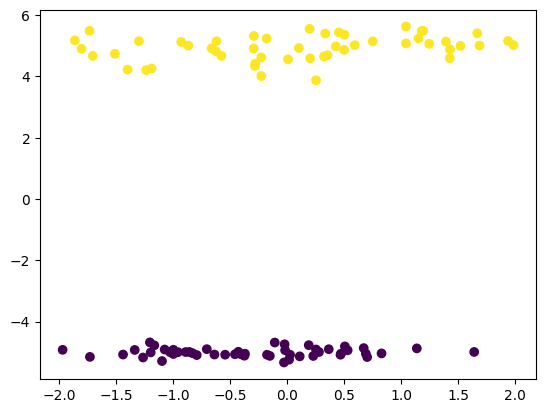

In [99]:
plt.scatter(X[:, 0], X[:, 1], c = y)

In [100]:
from sklearn.model_selection import train_test_split

In [101]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

In [102]:
# first doing it with the perceptron class
class perceptron:

    def __init__(self, lr, epochs):
        self.lr = lr
        self.epochs = epochs
        self.coefs = None

    def step(self, x):
        return 1 if x >= 0 else 0

    def fit(self, X_train, y_train):
        X_train = np.insert(X_train, 0, 1, axis= 1)
        self.coefs = np.ones(X_train.shape[1])
        for i in range(self.epochs):
            j = np.random.randint(0, X_train.shape[0])
            y_hat = self.step(np.dot(self.coefs, X_train[j]))
            self.coefs = self.coefs + self.lr * (y_train[j] - y_hat) * X_train[j]

In [103]:
pr = perceptron(0.01, 1000)

In [104]:
pr.fit(X_train, y_train)

In [105]:
pr.coefs

array([1., 1., 1.])

In [106]:
m = -(pr.coefs[1] / pr.coefs[2])
b = -(pr.coefs[0] / pr.coefs[2])

In [107]:
x_input = np.linspace(-3, 3, 100)
y_input = m * x_input + b

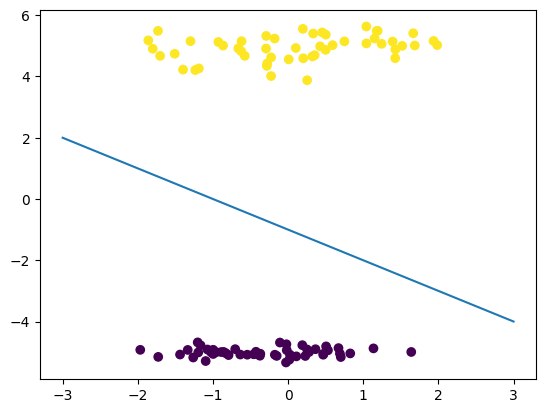

In [108]:
plt.scatter(X[:, 0], X[:, 1], c = y)
plt.plot(x_input, y_input)

In [109]:
# now doing the same thing by using logistic regression

In [110]:
class logistci_reg:

    def __init__(self, lr, epochs):
        self.lr = lr
        self.epochs = epochs
        self.coeffs = None

    def sigmoid(self, x):
        return round(1/ (1 + np.exp(-x)), 2)

    def fit(self, X_train, y_train):
        X_train = np.insert(X_train, 0, 1, axis= 1)
        self.coeffs = np.ones(X_train.shape[1])
        for i in range(self.epochs):
            j = np.random.randint(0, X_train.shape[0])
            y_hat = self.sigmoid(np.dot(self.coeffs, X_train[j]))
            self.coeffs = self.coeffs + self.lr * (y_hat - y_train[j]) * X_train[j]

In [111]:
lg = logistci_reg(0.01, 1000)

In [112]:
lg.fit(X_train, y_train)

In [113]:
m1 = -(lg.coeffs[1] / lg.coeffs[2])
b1 = -(lg.coeffs[0] / lg.coeffs[2])

In [114]:
x_input_2 = np.linspace(-3, 3, 100)
y_input_2 = m1 * x_input_2 + b1

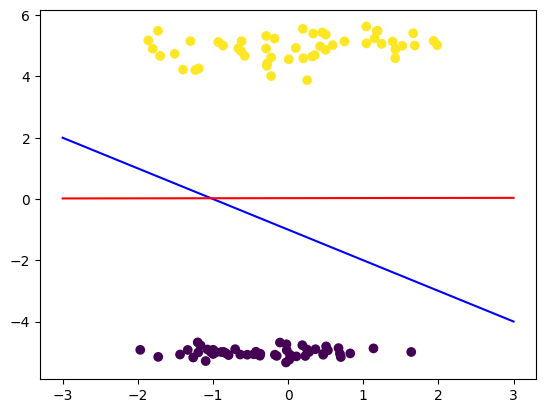

In [115]:
plt.scatter(X[:, 0], X[:, 1], c = y)
plt.plot(x_input, y_input, color = 'blue')
plt.plot(x_input_2, y_input_2, color = 'red')